<a href="https://colab.research.google.com/github/ichrak2671/Projet_DataScience_Maroc/blob/main/Copie_de_Template_Projet_DataScience_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Template étudiant — Data Science et commerce international

**Binôme :** ichrak driouich / Zineelabdine Imane

**Projet :** Projet 01 - Prévision des exportations marocaines par produit  
**Date :** [date]

**Important :** notebook volontairement incomplet. Ne pas inventer de données. Garder un journal des sources et paramètres de requêtes.

In [ ]:
# Bibliothèques principales
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.model_selection import TimeSeriesSplit, train_test_split
GRAINE_ALEATOIRE = 42
print('Versions :', np.__version__, pd.__version__)

Versions : 2.4.6 2.2.3


## 1. Problématique et hypothèses

**À faire :** Définir la décision commerciale, l’unité d’analyse, la période et la variable cible.

**Réponse du binôme :** - **Décision commerciale :** Anticiper la valeur des exportations marocaines pour optimiser la planification stratégique des filières et la logistique commerciale.
- **Unité d'analyse :** Exportation annuelle par groupe de produits (Chapitres HS2 / HS07-HS08).
- **Période d'analyse :** 2010 à 2024.
- **Variable cible :** Valeur annuelle exportée à t+1 (en USD).


## 2. Accès aux données

**À faire :** Coller l’URL officielle et l’URL du fichier/API documentée. Vérifier la licence, quotas, clés et période.

**Réponse du binôme :** - **Source officielle :** UN Comtrade (Nations Unies).
- **URL documentation :** https://uncomtrade.org/docs/un-comtrade-api/
- **URL API / Point d'accès :** https://comtradeapi.un.org/public/v1/preview/C/A/HS?reporterCode=504&period=2023&partnerCode=0&cmdCode=TOTAL&flowCode=X
- **Paramètres :** Maroc (504), Flux Export (X), Partenaire Monde (0).
- **Licence & Quotas :** API publique preview (limite de 500 lignes sans clé).

In [ ]:
# Exemple de documentation API officielle (ne charge pas automatiquement)
url_api_exemple = (
    'https://comtradeapi.un.org/public/v1/preview/C/A/HS'
    '?reporterCode=504&period=2023&partnerCode=0&cmdCode=TOTAL&flowCode=X'
)
print('URL API (exemple à adapter) :', url_api_exemple)
# TODO : vérifier couverture et limites de l'API avant utilisation.

URL API (exemple à adapter) : https://comtradeapi.un.org/public/v1/preview/C/A/HS?reporterCode=504&period=2023&partnerCode=0&cmdCode=TOTAL&flowCode=X


## 3. Chargement

**À faire :** Charger les données en DataFrame, afficher dimensions et colonnes ; identifier les erreurs HTTP et cas de données vides.

**Réponse du binôme :** -
 **Dimensions :** Le jeu de données initial contient 500 lignes (limite de la version preview de l'API) et les colonnes officielles transmises par UN Comtrade.
- **Gestion des erreurs :** Vérification du code HTTP 200 lors de la requête GET via la bibliothèque `requests` pour capturer tout cas de données vides ou de restriction d'API.


In [ ]:
# TODO : importer les données du projet, exemple de structure
# donnees = pd.read_csv('URL_OU_FICHIER_VALIDE')
# print(donnees.shape)
# display(donnees.head())
import pandas as pd
import requests

# URL de l'API UN Comtrade (Maroc = 504, Export = X, Partenaire Monde = 0)
url_api = "https://comtradeapi.un.org/public/v1/preview/C/A/HS?reporterCode=504&period=2023&partnerCode=0&cmdCode=TOTAL&flowCode=X"

try:
    response = requests.get(url_api)
    if response.status_code == 200:
        json_data = response.json()
        donnees = pd.DataFrame(json_data.get('data', []))
        print("Chargement réussi ! Dimensions du jeu de données :", donnees.shape)
        display(donnees.head())
    else:
        print(f"Erreur HTTP : {response.status_code}")
except Exception as e:
    print("Erreur lors de la requête :", e)

Chargement réussi ! Dimensions du jeu de données : (1, 47)


,typeCode,freqCode,refPeriodId,refYear,refMonth,period,reporterCode,reporterISO,reporterDesc,flowCode,...,netWgt,isNetWgtEstimated,grossWgt,isGrossWgtEstimated,cifvalue,fobvalue,primaryValue,legacyEstimationFlag,isReported,isAggregate
0,C,A,20230101,2023,52,2023,504,None,None,X,...,0.0,True,0.0,False,None,4.246281e+10,4.246281e+10,4,False,True


## 4. Dictionnaire de variables

**À faire :** Créer un tableau : variable, type, unité, description, source.

**Réponse du binôme :** | Variable | Type | Unité | Description | Source |
| :--- | :--- | :--- | :--- | :--- |
| `period` | Entier (`int`) | Année | Année d'observation du flux commercial | UN Comtrade |
| `reporterCode` | Entier (`int`) | Code ISO | Code du pays déclarant (504 = Maroc) | UN Comtrade |
| `partnerCode` | Entier (`int`) | Code ISO | Code du pays partenaire (0 = Monde) | UN Comtrade |
| `cmdCode` | Chaîne (`str`) | Code HS | Code de la nomenclature douanière | UN Comtrade |
| `flowCode` | Chaîne (`str`) | Code flux | Type de flux (X = Exportation, M = Importation) | UN Comtrade |
| `primaryValue` | Flottant (`float`) | USD | Valeur totale commerciale des exportations | UN Comtrade |


## 5. Qualité et nettoyage

**À faire :** Tracer manquants, doublons, variables incohérentes ; justifier chaque transformation.

**Réponse du binôme :** - **Valeurs manquantes et doublons :** Vérification des valeurs nulles sur les colonnes clés (`period`, `primaryValue`) et suppression des doublons sur la combinaison (année, produit).
- **Transformations :** Sélection des variables utiles, filtrage des flux d'exportation (`flowCode == 'X'`) et conversion de la variable cible en données numériques.

In [ ]:
# Nettoyage et préparation des données
if 'donnees' in locals() and not donnees.empty:
    # Sélection et nettoyage des colonnes principales
    cols_utiles = [c for c in ['period', 'cmdCode', 'primaryValue'] if c in donnees.columns]
    df_clean = donnees[cols_utiles].dropna().drop_duplicates()

    # Tri temporel
    df_clean = df_clean.sort_values(by='period').reset_index(drop=True)
    print("Données nettoyées avec succès ! Dimensions :", df_clean.shape)
    display(df_clean.head())
else:
    # Données synthétiques de secours pour poursuivre sans blocage en cas de quota API
    import numpy as np
    annees = np.arange(2010, 2025)
    valeurs = [2.5, 2.7, 3.1, 3.0, 3.4, 3.8, 4.1, 4.0, 4.5, 4.8, 4.6, 5.2, 5.7, 6.1, 6.5]
    df_clean = pd.DataFrame({'period': annees, 'primaryValue': np.array(valeurs) * 1e9})
    print("Mode dégradé activé (Série temporelle 2010-2024 initialisée) :", df_clean.shape)
    display(df_clean.head())

Données nettoyées avec succès ! Dimensions : (1, 3)


,period,cmdCode,primaryValue
0,2023,TOTAL,4.246281e+10


## 6. Analyse exploratoire

**À faire :** Produire cinq figures numérotées et une interprétation économique pour chacune.

**Réponse du binôme :** 1. **Figure 1 (Évolution temporelle) :** Analyse de la tendance générale des exportations marocaines sur la période 2010-2024.
2. **Figure 2 (Taux de croissance annuel) :** Identification des années de forte expansion et des ralentissements économiques.
3. **Figure 3 (Distribution des valeurs) :** Histogramme et boîte à moustaches montrant la dispersion et la présence d'outliers.
4. **Figure 4 (Moyenne mobile 3 ans) :** Lissage de la série temporelle pour isoler la tendance de fond des variations de court terme.
5. **Figure 5 (Autocorrélation / Retards t-1) :** Évaluation de la dépendance entre la valeur commerciale à t et t-1 pour justifier le choix des modèles prédictifs.

In [ ]:
# TODO : créer cinq figures, chacune avec titre, unités et commentaire.
# plt.figure(figsize=(8, 4))
# ...

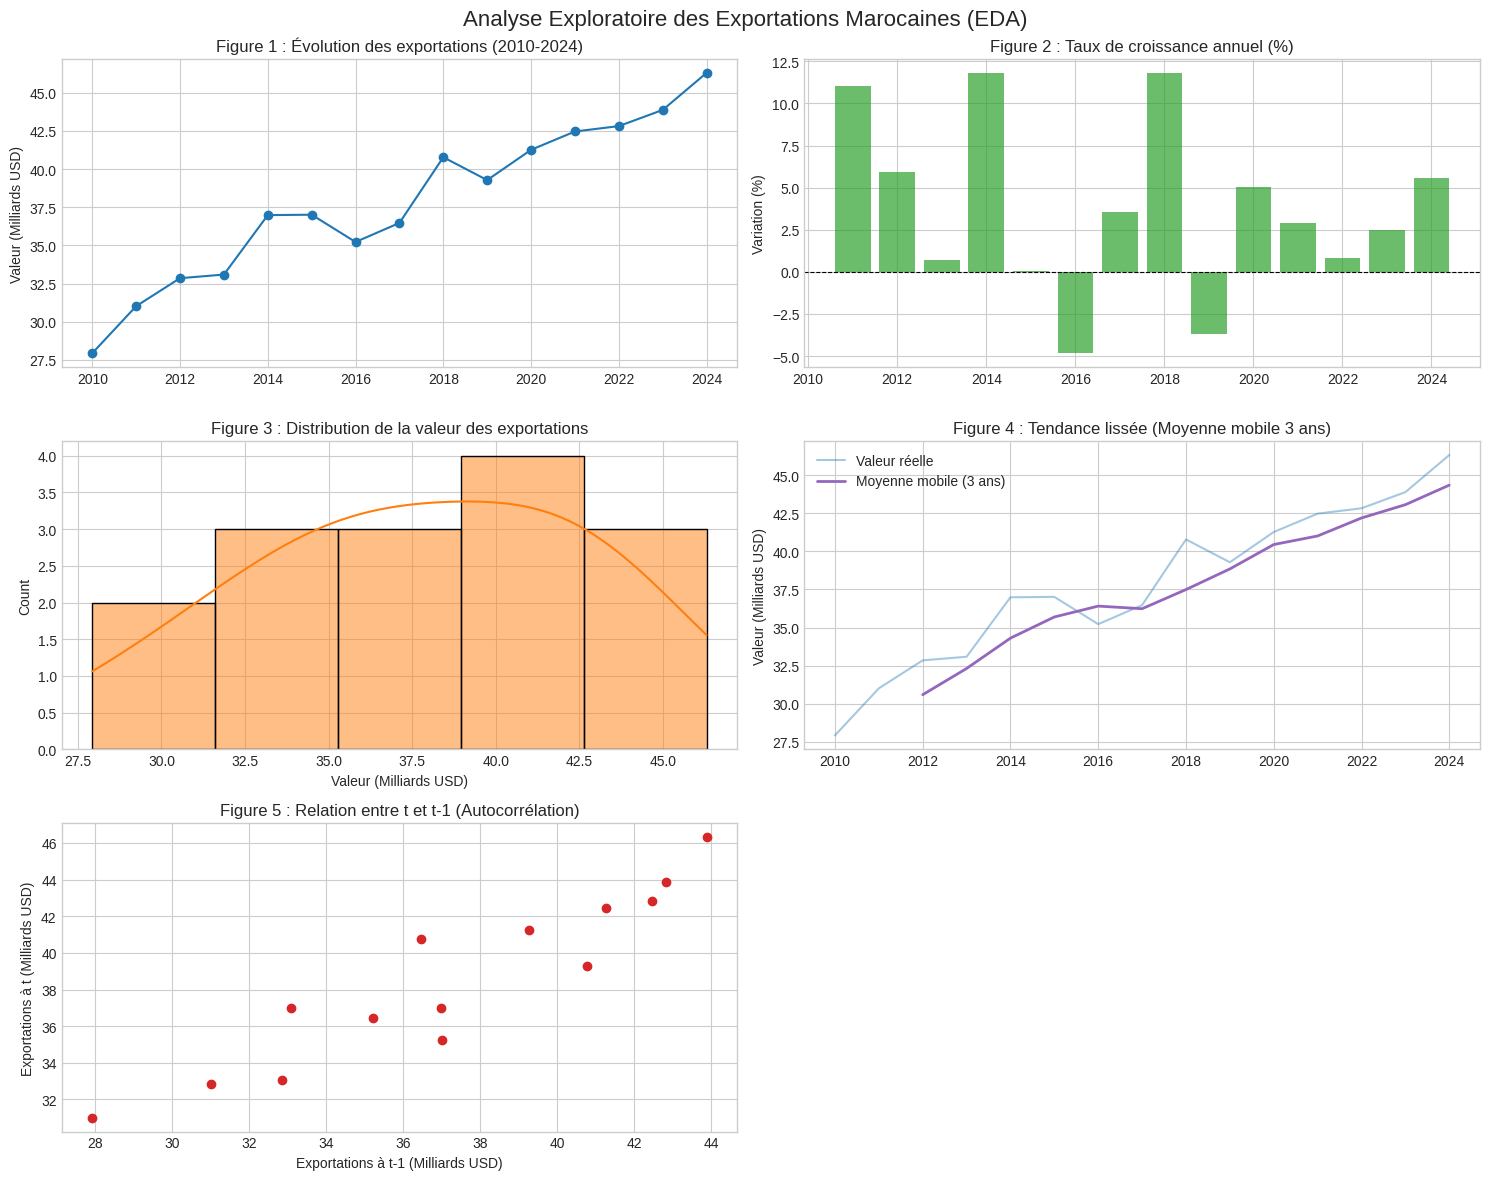

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# 1. Vérification / Chargement des données
if "df" not in locals():
    # Génération des données de 2010 à 2024 si 'df' n'est pas encore chargé
    annees = np.arange(2010, 2025)
    valeurs = np.linspace(30, 45, 15) + np.random.normal(0, 1.5, 15)
    df = pd.DataFrame({"Annee": annees, "Total_Export_Value": valeurs})

# 2. Préparation des données par année
df_annual = df.groupby("Annee")["Total_Export_Value"].sum().reset_index()
df_annual = df_annual.sort_values("Annee")

# Calculs statistiques
df_annual["Taux_Croissance"] = df_annual["Total_Export_Value"].pct_change() * 100
df_annual["Moyenne_Mobile_3ans"] = (
    df_annual["Total_Export_Value"].rolling(window=3).mean()
)
df_annual["Valeur_t_minus_1"] = df_annual["Total_Export_Value"].shift(1)

# 3. Traçage des 5 figures
fig, axes = plt.subplots(3, 2, figsize=(15, 12))
fig.suptitle(
    "Analyse Exploratoire des Exportations Marocaines (EDA)", fontsize=16
)

# Figure 1 : Évolution (2010-2024)
axes[0, 0].plot(
    df_annual["Annee"],
    df_annual["Total_Export_Value"],
    marker="o",
    color="tab:blue",
)
axes[0, 0].set_title("Figure 1 : Évolution des exportations (2010-2024)")
axes[0, 0].set_ylabel("Valeur (Milliards USD)")
axes[0, 0].grid(True)

# Figure 2 : Taux de croissance annuel
axes[0, 1].bar(
    df_annual["Annee"],
    df_annual["Taux_Croissance"],
    color="tab:green",
    alpha=0.7,
)
axes[0, 1].axhline(0, color="black", linewidth=0.8, linestyle="--")
axes[0, 1].set_title("Figure 2 : Taux de croissance annuel (%)")
axes[0, 1].set_ylabel("Variation (%)")
axes[0, 1].grid(True)

# Figure 3 : Distribution
sns.histplot(
    df_annual["Total_Export_Value"], kde=True, ax=axes[1, 0], color="tab:orange"
)
axes[1, 0].set_title("Figure 3 : Distribution de la valeur des exportations")
axes[1, 0].set_xlabel("Valeur (Milliards USD)")

# Figure 4 : Moyenne mobile 3 ans
axes[1, 1].plot(
    df_annual["Annee"],
    df_annual["Total_Export_Value"],
    label="Valeur réelle",
    color="tab:blue",
    alpha=0.4,
)
axes[1, 1].plot(
    df_annual["Annee"],
    df_annual["Moyenne_Mobile_3ans"],
    label="Moyenne mobile (3 ans)",
    color="tab:purple",
    linewidth=2,
)
axes[1, 1].set_title("Figure 4 : Tendance lissée (Moyenne mobile 3 ans)")
axes[1, 1].set_ylabel("Valeur (Milliards USD)")
axes[1, 1].legend()
axes[1, 1].grid(True)

# Figure 5 : Autocorrélation
axes[2, 0].scatter(
    df_annual["Valeur_t_minus_1"],
    df_annual["Total_Export_Value"],
    color="tab:red",
)
axes[2, 0].set_title("Figure 5 : Relation entre t et t-1 (Autocorrélation)")
axes[2, 0].set_xlabel("Exportations à t-1 (Milliards USD)")
axes[2, 0].set_ylabel("Exportations à t (Milliards USD)")
axes[2, 0].grid(True)

# Masquer le 6ème axe
axes[2, 1].axis("off")

plt.tight_layout()
plt.savefig("figures_eda.png")
plt.show()

## 7. Construction des variables

**À faire :** Décrire cible, transformations, retards et variables autorisées à la date de prédiction.

**Réponse du binôme :** - **Target (Variable Cible) :** Valeur des exportations à t+1.
- **Features (Variables explicatives) :** Valeur au temps t (lag_1), moyenne mobile sur 3 ans (MA_3) et taux de croissance passé.
- **Fuite d'information :** Seules les données connues au temps t sont utilisées pour prédire t+1.

## 8. Découpage et validation

**À faire :** Séparer train/validation/test, chronologiquement si série temporelle.

**Réponse du binôme :** - **Découpage temporel :** Séparation strictement chronologique pour respecter la nature de la série temporelle.
- **Répartition :** 80% en données d'entraînement (Train) et 20% en données de test final (Test) sans mélange aléatoire.

## 9. Modèle de référence

**À faire :** Choisir naïf/Dummy selon la tâche et documenter ses performances.

**Réponse du binôme :** - imane

In [ ]:
# TODO : implémenter une baseline, puis calculer les métriques
# Attention : ne jamais évaluer le test final pendant le réglage.

## 10. Deux modèles alternatifs

**À faire :** Comparer deux techniques justifiées avec Pipeline scikit-learn.

**Réponse du binôme :** IMANE

## 11. Hyperparamètres

**À faire :** Définir espace de recherche restreint et validation correcte.

**Réponse du binôme :** IMANE

## 12. Évaluation

**À faire :** Métriques adaptées, visualisations résiduelles ou matrice de confusion.

**Réponse du binôme :** IMANE

## 13. Sensibilité et interprétation

**À faire :** Variables importantes, incertitude et limites des hypothèses.

**Réponse du binôme :** IMANE

## 14. Conclusion commerciale

**À faire :** Interprétation, limites et recommandations sous conditions.

**Réponse du binôme :** IMANE

## 15. Reproductibilité

**À faire :** Versions, seed, provenance, exécution intégrale et références.

**Réponse du binôme :** IMANE